# GaggiMate shot pipeline

Fetches everything new from the machine and decodes it. Run all cells from top to bottom.

1. **Shot logs**: downloads new `.slog` files to `data/slog` (`sync_shots.py`)
2. **Annotations**: fetches your notes as `data/slog/<id>.json` (`fetch_annotations.py`)
3. **Decode**: writes CSV files and charts to `data/decoded` (`decode_slog.py`)
4. **Look at the data**

Needs `GAGGIA_IP` in `.env`, the machine switched on, and:
`pip install httpx websockets python-dotenv pandas matplotlib`

In [3]:
import pandas as pd
from IPython.display import Image, display

import decode_slog
from fetch_annotations import fetch_annotations_async
from sync_shots import sync_shots

## 1. New shot logs

In [4]:
new_shots = sync_shots()
new_shots

index unchanged - nothing to do


[]

## 2. Annotations
Fetches the notes of all shots that have notes, and saves only new or changed ones.

In [5]:
changed_notes = await fetch_annotations_async()
changed_notes

shots with notes: 0


[]

## 3. Decode
`shots.csv` and `samples.csv` are rebuilt every time; per-shot CSV and PNG files are only created for new shots.

In [7]:
decode_slog.main(["--plot"])

Decoded 153/153 shots (0 new), 24245 samples -> data/decoded/


## 4. Look at the data

In [8]:
shots = pd.read_csv("data/decoded/shots.csv", dtype={"shot_id": str})
samples = pd.read_csv("data/decoded/samples.csv", dtype={"shot_id": str})
shots = shots.sort_values("start_time_utc")
print(f"{len(shots)} shots, {len(samples)} samples")
shots.tail(10)

153 shots, 24245 samples


,shot_id,version,start_time_utc,profile_id,profile_name,duration_s,sample_count,final_weight_g,final_exit_reason,brew_delay_ms,incomplete,phases
143,000284,5,2026-07-12T08:11:21+00:00,Aq8QPAqeyp,Blooming miscela Napoli,37.910,147,38.4,unknown,0,False,Bloom Prewet > Bloom Pause > Ramp to Brew Pres...
144,000285,5,2026-07-12T11:59:28+00:00,K1LAPcRsE1,Default,8.732,29,0.0,unknown,0,False,Brew
145,000286,5,2026-07-12T12:01:43+00:00,K1LAPcRsE1,Default,10.903,38,0.0,unknown,0,False,Brew
146,000287,5,2026-07-12T12:03:54+00:00,K1LAPcRsE1,Default,9.330,31,0.0,unknown,0,False,Brew
147,000288,5,2026-07-12T12:04:20+00:00,K1LAPcRsE1,Default,8.195,28,0.0,unknown,0,False,Brew
148,000289,5,2026-07-12T12:12:54+00:00,K1LAPcRsE1,Default,8.381,28,0.0,unknown,0,False,Brew
149,000290,5,2026-07-12T12:13:43+00:00,K1LAPcRsE1,Default,16.496,59,0.0,unknown,0,False,Brew
150,000291,5,2026-07-12T12:14:13+00:00,K1LAPcRsE1,Default,8.291,28,0.0,unknown,0,False,Brew
151,000292,5,2026-07-13T06:49:04+00:00,Aq8QPAqeyp,Blooming miscela Napoli,48.409,187,38.4,unknown,0,False,Bloom Prewet > Bloom Pause > Ramp to Brew Pres...
152,000293,5,2026-07-13T06:56:38+00:00,Aq8QPAqeyp,Blooming miscela Napoli,48.329,187,38.2,unknown,0,False,Bloom Prewet > Bloom Pause > Ramp to Brew Pres...


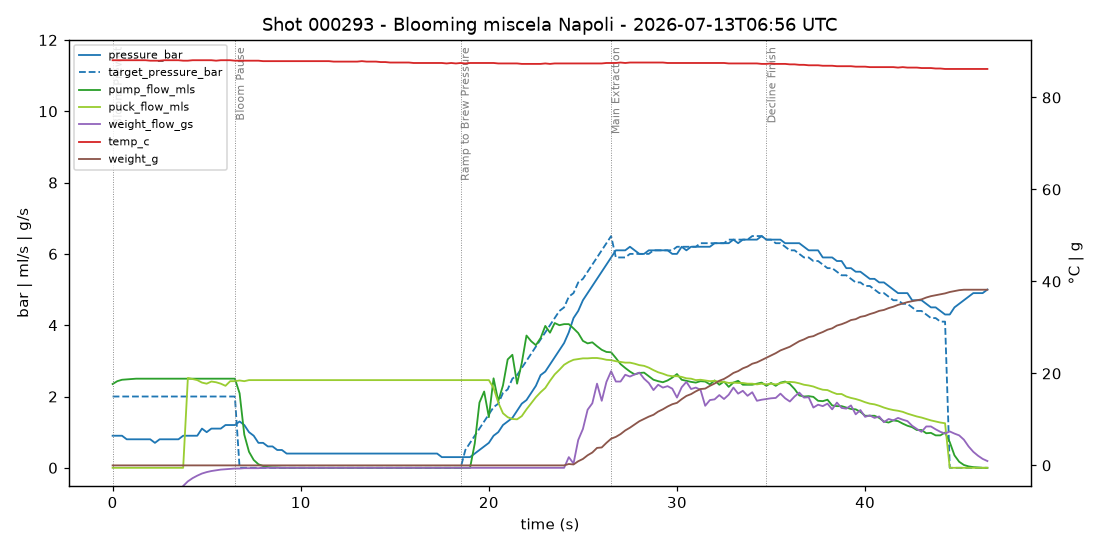

,count,mean,std,min,25%,50%,75%,max
sample_idx,187.0,93.000000,54.126395,0.00,46.500,93.00,139.500,186.00
t_ms,187.0,23250.000000,13531.598822,0.00,11625.000,23250.00,34875.000,46500.00
t_s,187.0,23.250000,13.531599,0.00,11.625,23.25,34.875,46.50
phase_number,187.0,2.155080,1.415169,0.00,1.000,2.00,4.000,4.00
target_temp_c,187.0,88.000000,0.000000,88.00,88.000,88.00,88.000,88.00
temp_c,187.0,87.419786,0.531769,86.20,87.300,87.50,87.900,88.10
target_pressure_bar,187.0,3.043850,2.534727,0.00,0.000,2.20,5.800,6.50
pressure_bar,187.0,3.148663,2.478648,0.30,0.650,2.90,5.900,6.50
pump_flow_mls,187.0,1.655348,1.245550,0.00,0.020,2.03,2.500,4.06
target_flow_mls,187.0,0.360963,0.881058,0.00,0.000,0.00,0.000,2.50


In [9]:
latest = shots["shot_id"].iloc[-1]
display(Image(f"data/decoded/per_shot/{latest}.png"))
samples[samples["shot_id"] == latest].describe().T